In [83]:
print("aman")

aman


In [84]:
import os
from langgraph.graph import StateGraph,START,END
from langgraph.graph.message import add_messages
from dotenv import load_dotenv
from langchain_core.messages import HumanMessage,AIMessage,BaseMessage
from typing import TypedDict,Annotated
from langchain_groq import ChatGroq
from langgraph.checkpoint.memory import MemorySaver
from langgraph.types import interrupt,Command

load_dotenv()
groq_api_key=os.getenv("GROQ_API_KEY")
llm = ChatGroq(model="openai/gpt-oss-20b",groq_api_key=groq_api_key)

In [85]:
class ChatState(TypedDict):
    messages:Annotated[list[BaseMessage],add_messages]

In [86]:
def chat_node(state:ChatState):
    decision = interrupt({
        "type": "approval",
        "reason": "Model is about to answer a user question.",
        "question": state["messages"][-1].content,
        "instruction": "Approve this question? yes/no"
    })
    if decision["approved"] == 'no':
        return {"messages": [AIMessage(content="Not approved.")]}

    else:
        response = llm.invoke(state["messages"])
        return {"messages": [response]}

In [87]:
graph=StateGraph(ChatState)

graph.add_node('chat_node',chat_node)

graph.add_edge(START,'chat_node')
graph.add_edge('chat_node',END)

checkpointer=MemorySaver()

workflow=graph.compile(checkpointer=checkpointer)

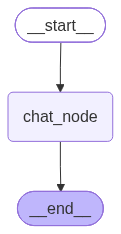

In [88]:
workflow

In [89]:
# Create a new thread id for this conversation
config = {"configurable": {"thread_id": '1234'}}

# ---- STEP 1: user asks a question ----
initial_input = {
    "messages": [
        ("user", "tell about random forest")
    ]
}

# Invoke the graph for the first time
result = workflow.invoke(initial_input, config=config)

In [90]:
result

{'messages': [HumanMessage(content='tell about random forest', additional_kwargs={}, response_metadata={}, id='fc46b39e-72f2-4f30-9c43-6b5efab00ce7')],
 '__interrupt__': [Interrupt(value={'type': 'approval', 'reason': 'Model is about to answer a user question.', 'question': 'tell about random forest', 'instruction': 'Approve this question? yes/no'}, id='f73aac9d54721475e03361891a611786')]}

In [91]:
message=result['__interrupt__'][0].value
message

{'type': 'approval',
 'reason': 'Model is about to answer a user question.',
 'question': 'tell about random forest',
 'instruction': 'Approve this question? yes/no'}

In [92]:
user_input=input(f"\nBackend message - {message} \n Approve this question? (y/n): ")

In [93]:
final_result=workflow.invoke(
    Command(resume={"approved":user_input}),
    config=config
)
final_result

{'messages': [HumanMessage(content='tell about random forest', additional_kwargs={}, response_metadata={}, id='fc46b39e-72f2-4f30-9c43-6b5efab00ce7'),
  AIMessage(content='## Random Forest – A Quick & Deep Dive\n\nRandom Forest is one of the most popular and powerful supervised‑learning algorithms in the data‑science toolbox. It sits at the intersection of two ideas:\n\n| Idea | What it does | Why it matters |\n|------|--------------|----------------|\n| **Bagging (Bootstrap Aggregating)** | Train many independent trees on random samples of the data (with replacement). | Reduces variance by averaging predictions from many noisy models. |\n| **Feature Randomness** | At each split, consider only a random subset of features rather than all of them. | Prevents strong predictors from dominating, encourages tree diversity, and speeds up training. |\n\nThe combination of these two mechanisms produces an ensemble that is **robust, accurate, and interpretable** (to a degree). Below is a systema

In [94]:
from rich.console import Console
from rich.markdown import Markdown

console=Console()
console.print(Markdown(final_result["messages"][-1].content))

Random Forest – A Quick & Deep Dive                                                                                

Random Forest is one of the most popular and powerful supervised‑learning algorithms in the data‑science toolbox.  
It sits at the intersection of two ideas:                                                                          

                                                                                                                   
 Idea                             What it does                             Why it matters                          
 ───────────────────────────────────────────────────────────────────────────────────────────────────────────────── 
 Bagging (Bootstrap Aggregating)  Train many independent trees on random   Reduces variance by averaging           
                                  samples of the data (with replacement).  predictions from many noisy models.     
 Feature Randomness               At each split, consider only a random    Prevents strong predictors from         
                                  subset of features rather than all of    dominating, encourages tree diversity,  
                                  them.                                    and speeds up training.                 
                                                                                                                   

The combination of these two mechanisms produces an ensemble that is robust, accurate, and interpretable (to a     
degree). Below is a systematic walk‑through of the algorithm, its math, practical usage, and common pitfalls.      

-------------------------------------------------------------------------------------------------------------------

1. What is a Random Forest?                                                                                        

A Random Forest is an ensemble of decision trees. Each tree is trained on a bootstrap sample of the training data  
and, when deciding how to split a node, it selects the best split among a random subset of features. The final     
prediction is:                                                                                                     

 • Classification: majority vote (mode) of the tree predictions.                                                   
 • Regression: average of the tree predictions (mean).                                                             

Because each tree sees a slightly different view of the data and the feature space, they are decorrelated, and     
their aggregate predictions are far less noisy than any single tree.                                               

-------------------------------------------------------------------------------------------------------------------

2. Core Steps of the Algorithm                                                                                     

                                                                                                                   
 Step                      What Happens                                Why It Matters                              
 ───────────────────────────────────────────────────────────────────────────────────────────────────────────────── 
 1. Bootstrap sampling     For each tree, sample n_samples rows from   Creates diverse training sets; each tree is 
                           the training set with replacement.          built on a slightly different dataset.      
 2. Grow a tree            Build a decision tree to full depth (or     The random feature selection ensures trees  
                           until a stopping rule). At each node:  -    differ even if the data are similar.        
                           Randomly pick mtry features from the total                                              
                           p features.  - Find the best split among                                                
                           those mtry feature